In [18]:
# Librairies import
import pandas as pd
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# OpenVaccine: COVID-19 mRNA Vaccine Degradation Prediction: Urgent need to bring the COVID-19 vaccine to mass production (EDA)

## 1. Data Import

In [19]:
train_df = pd.read_json('../data/train.json.zip', lines=True, compression='zip')
test_df = pd.read_json('../data/test.json.zip', lines=True, compression='zip')

print(f"Train : {train_df.shape}")
print(f"Test  : {test_df.shape}")

Train : (2400, 19)
Test  : (3634, 7)


In [20]:
sample = train_df.iloc[0]

print("ID de la molécule :", sample['id'])
print("Séquence (107 nucléotides) :", sample['sequence'])
print("Structure secondaire       :", sample['structure'])
print("Longueur de reactivity     :", len(sample['reactivity'])) # 68 valeurs

ID de la molécule : id_001f94081
Séquence (107 nucléotides) : GGAAAAGCUCUAAUAACAGGAGACUAGGACUACGUAUUUCUAGGUAACUGGAAUAACCCAUACCAGCAGUUAGAGUUCGCUCUAACAAAAGAAACAACAACAACAAC
Structure secondaire       : .....((((((.......)))).)).((.....((..((((((....))))))..)).....))....(((((((....))))))).....................
Longueur de reactivity     : 68


In [21]:
# Configuration du style des graphiques
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# ---------------------------------------------------------
# 2. Vérification des données manquantes
# ---------------------------------------------------------
print("\n1. VÉRIFICATION DES DONNÉES MANQUANTES")
missing_values = train_df.isnull().sum()
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "Aucune valeur manquante détectée dans le DataFrame !")

# ---------------------------------------------------------
# 3. Distribution des longueurs de séquences et des cibles
# ---------------------------------------------------------
train_df['seq_length'] = train_df['sequence'].apply(len)
train_df['seq_scored_length'] = train_df['seq_scored']

print("\n2. STATISTIQUES DES LONGUEURS DE SÉQUENCES (TRAIN)")
print(train_df[['seq_length', 'seq_scored_length']].value_counts())





1. VÉRIFICATION DES DONNÉES MANQUANTES
Aucune valeur manquante détectée dans le DataFrame !

2. STATISTIQUES DES LONGUEURS DE SÉQUENCES (TRAIN)
seq_length  seq_scored_length
107         68                   2400
Name: count, dtype: int64


## 1. Distribution des cibles 

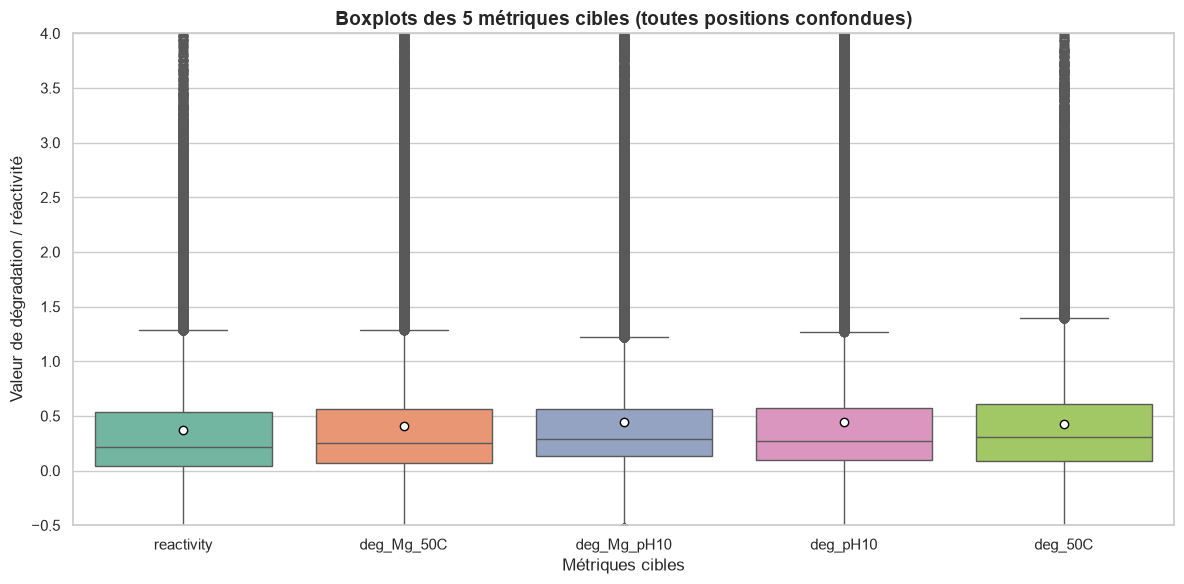

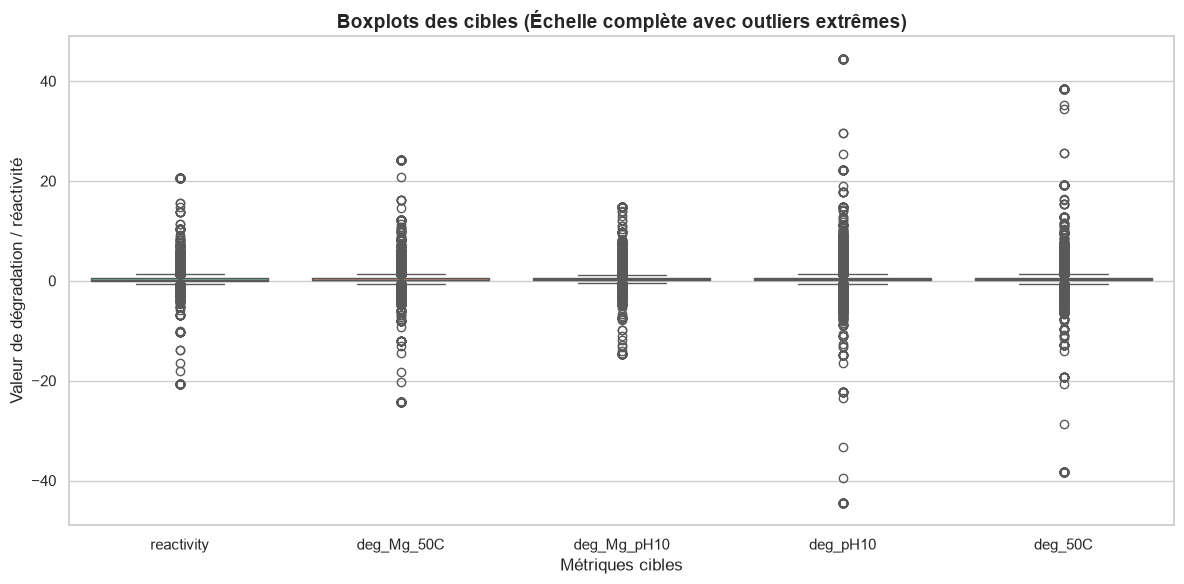

In [22]:

target_cols = ['reactivity', 'deg_Mg_50C', 'deg_Mg_pH10', 'deg_pH10', 'deg_50C']

# 1. Aplatir les listes de valeurs pour chaque cible
all_targets = {col: np.concatenate(train_df[col].values) for col in target_cols}
df_targets_flat = pd.DataFrame(all_targets)

# 2. Graphique Boxplot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_targets_flat, palette="Set2", showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black"})

plt.title("Boxplots des 5 métriques cibles (toutes positions confondues)", fontsize=14, fontweight='bold')
plt.ylabel("Valeur de dégradation / réactivité")
plt.xlabel("Métriques cibles")
plt.ylim(-0.5, 4.0)  # Zoom sur la zone principale (0 à 4) pour éviter d'écraser la boîte à cause des très grands outliers
plt.tight_layout()
plt.show()

# 3. Zoom spécifique sans réduire l'échelle pour visualiser tous les outliers extrêmes
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_targets_flat, palette="Set2")
plt.title("Boxplots des cibles (Échelle complète avec outliers extrêmes)", fontsize=14, fontweight='bold')
plt.ylabel("Valeur de dégradation / réactivité")
plt.xlabel("Métriques cibles")
plt.tight_layout()
plt.show()


Cette figure présente la distribution globale des cinq variables cibles mesurées à l'échelle du nucléotide. On observe que la majorité des valeurs sont très concentrées autour de $0$ et $1$, avec un interquartile très étroit. Cependant, les données contiennent de nombreux outliers extrêmes, tant positifs (dégradations/réactivités élevées atteignant $> 20$ à $40$) que négatifs (bruit de mesure expérimental pouvant descendre jusqu'à $-40$, notamment sur deg_pH10 et deg_50C).   
Impact sur le modèle : Cette forte asymétrie et la présence de bruit expérimental justifient l'utilisation d'une métrique robuste et l'intérêt d'un sous-pondérage ou filtrage basé sur le ratio signal/bruit (SN_filter)

## 2. Distribution des caractères (séquence, structure, boucles)

C:\Users\easte\AppData\Local\Temp\ipykernel_99000\2703522306.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=seq_counts.index, y=seq_counts.values, ax=axes[0], palette="viridis")
C:\Users\easte\AppData\Local\Temp\ipykernel_99000\2703522306.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=struct_pct.index, y=struct_pct.values, ax=axes[1], palette="magma")
C:\Users\easte\AppData\Local\Temp\ipykernel_99000\2703522306.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=loop_counts.index, y=loop_counts.values, ax=axes[2], palette=

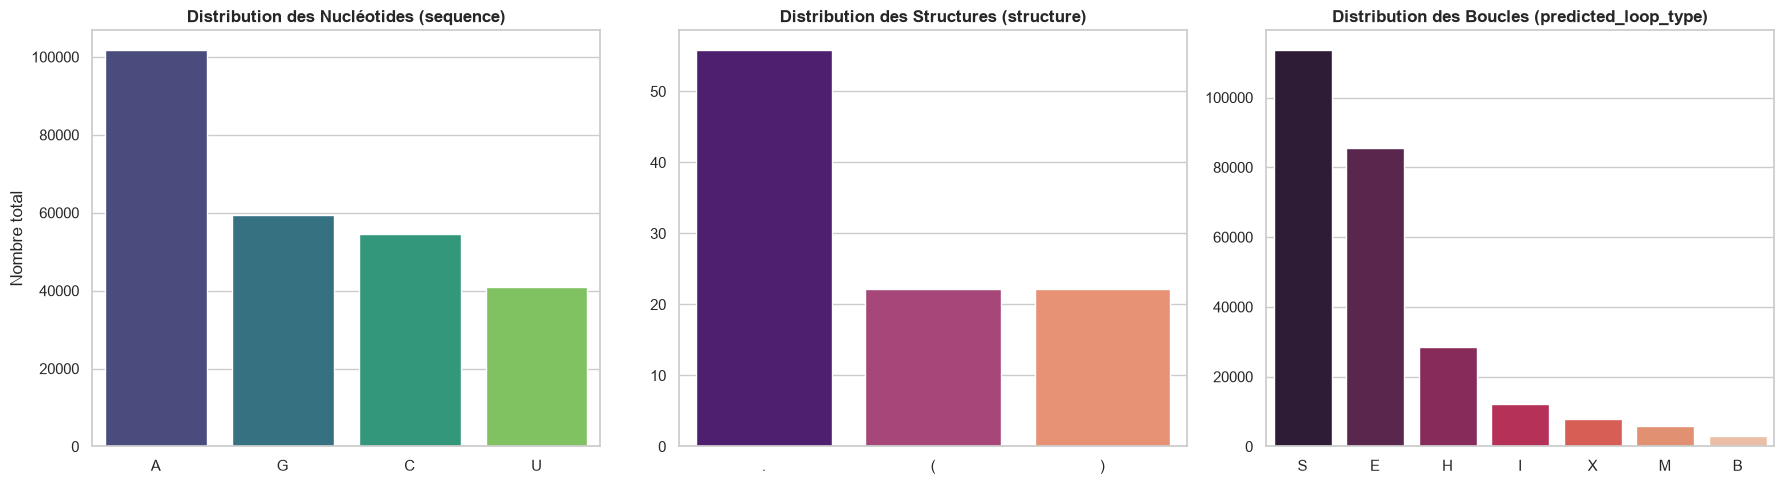

In [26]:

def get_char_counts(series):
    all_chars = "".join(series.tolist())
    return pd.Series(list(all_chars)).value_counts()

seq_counts = get_char_counts(train_df['sequence'])
struct_pct = get_char_counts(train_df['structure']) / len("".join(train_df['structure'].tolist())) * 100
loop_counts = get_char_counts(train_df['predicted_loop_type'])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Séquences (Nucléotides)
sns.barplot(x=seq_counts.index, y=seq_counts.values, ax=axes[0], palette="viridis")
axes[0].set_title("Distribution des Nucléotides (sequence)", fontweight='bold')
axes[0].set_ylabel("Nombre total")
axes[0].set_xlabel("")

# Structure secondaire
sns.barplot(x=struct_pct.index, y=struct_pct.values, ax=axes[1], palette="magma")
axes[1].set_title("Distribution des Structures (structure)", fontweight='bold')
axes[1].set_xlabel("")

# Types de boucles
sns.barplot(x=loop_counts.index, y=loop_counts.values, ax=axes[2], palette="rocket")
axes[2].set_title("Distribution des Boucles (predicted_loop_type)", fontweight='bold')
axes[2].set_xlabel("")

plt.tight_layout()
plt.show()


Description : Ce triptyque illustre la répartition des caractéristiques d'entrée :   
Nucléotides : L'adénine (A) est prédominante ($> 100\ 000$ occurrences), suivie de la guanine (G), la cytosine (C) et l'uracile (U).   
Structure secondaire : Les bases non appariées (.) sont environ deux fois plus nombreuses que les bases appariées formant des hélices (( et )).   Types de boucles : Les catégories dominantes sont les tiges/stems (S) et les extrémités (E), suivies des boucles en épingle/hairpin (H) et internes (I). 

## 3. Analyse des corrélations entre les 5 cibles 

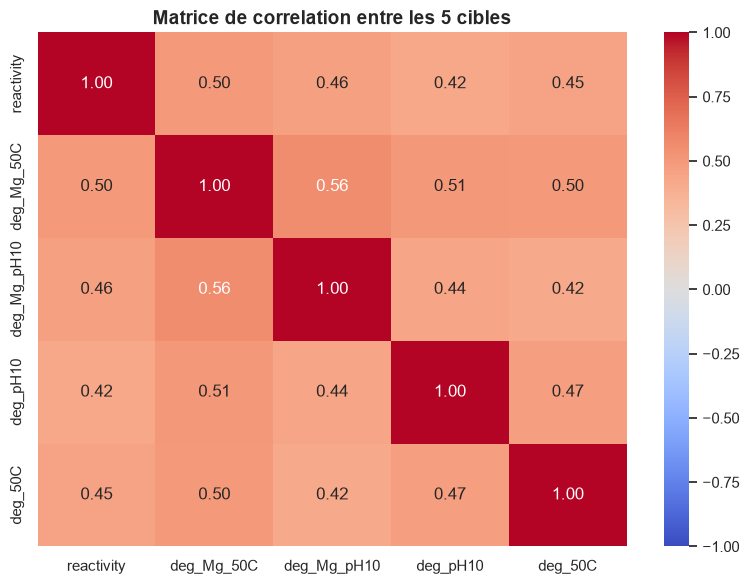

In [ ]:
targets_df = pd.DataFrame(all_targets)
plt.figure(figsize=(8, 6))
sns.heatmap(targets_df.corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Matrice de correlation entre les 5 cibles", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

La heatmap de corrélation montre que les cinq métriques de dégradation/réactivité sont toutes modérément à fortement corrélées positivement entre elles (coefficients variant entre $0,42$ et $0,56$). Les corrélations les plus fortes sont observées entre deg_Mg_50C et deg_Mg_pH10 ($r = 0,56$) ainsi qu'entre deg_Mg_50C et deg_pH10 / deg_50C ($r \ge 0,50$). 

## 4. Réactivité par type de Boucle

C:\Users\easte\AppData\Local\Temp\ipykernel_99000\4133170794.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='loop_type', y='reactivity', data=df_loop_react, palette="Set3")


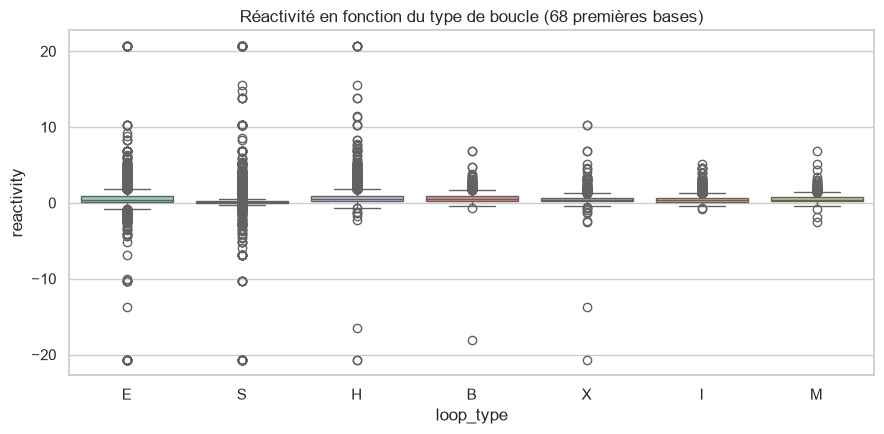

In [ ]:
# Aplatir les types de boucles et la réactivité sur les 68 premières bases
loops_flat = np.concatenate(train_df['predicted_loop_type'].apply(lambda x: list(x[:68])).values)
react_flat = np.concatenate(train_df['reactivity'].values)

df_loop_react = pd.DataFrame({'loop_type': loops_flat, 'reactivity': react_flat})

plt.figure(figsize=(9, 4.5))
sns.boxplot(x='loop_type', y='reactivity', data=df_loop_react, palette="Set3")
plt.title("Réactivité en fonction du type de boucle (68 premières bases)")
# plt.ylim(-0.5, 3.5)
plt.tight_layout()
# plt.savefig(f"{report_dir}/fig4_reactivity_by_loop.png", dpi=300)
# plt.close()
plt.show()

Ce boxplot détaille la réactivité des $68$ premières bases évaluées en fonction de leur contexte structural local (loop_type). On constate clairement que les régions en tige (S) présentent une réactivité quasi nulle et une variance très faible. À l'inverse, les régions flexibles comme les boucles (H, E, B) ou les extrémités présentent une réactivité nettement plus élevée et une dispersion importante.   
**Impact sur le modèle** : Cela démontre scientifiquement que la séquence seule ne suffit pas : la structure secondaire 2D apporte un signal prédictif essentiel pour anticiper la stabilité.

## 5. Visualisation d'une matrice BPPS

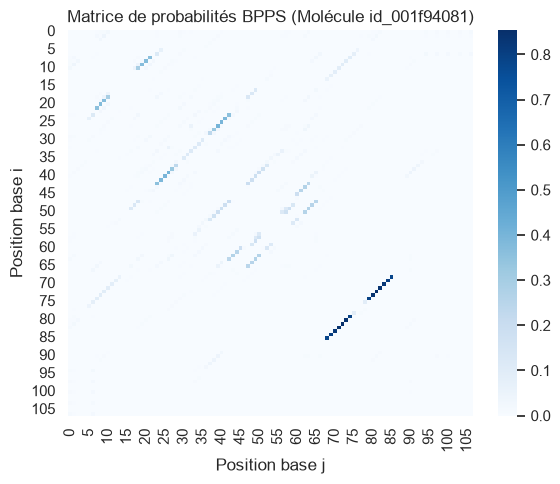

In [15]:
sample_id = train_df.iloc[0]['id']
bpps_path = f"../data/bpps/{sample_id}.npy"

if os.path.exists(bpps_path):
    bpps_matrix = np.load(bpps_path)
    plt.figure(figsize=(6, 5))
    sns.heatmap(bpps_matrix, cmap="Blues")
    plt.title(f"Matrice de probabilités BPPS (Molécule {sample_id})")
    plt.xlabel("Position base j")
    plt.ylabel("Position base i")
    plt.tight_layout()
    # plt.savefig(f"{report_dir}/fig5_bpps_example.png", dpi=300)
    # plt.close()
    plt.show()

Représentation sous forme de heatmap de la matrice BPPS (Base Pairing Probability Matrix) $107 \times 107$ pour une molécule d'exemple (id_001f94081). Les diagonales secondaires très marquées (notamment entre les positions $70-85$ et $70-85$) indiquent des paires de bases appariées stables formant la double hélice d'ARN.   
**Impact sur le modèle** : Cette matrice fournit l'information spatiale/géométrique sous forme de graphe, indispensable pour les architectures de type GNN ou Transformers à attention 2D.

## 6. Distribution du Signal/Bruit (signal_to_noise) et SN_filter

C:\Users\easte\AppData\Local\Temp\ipykernel_99000\752850403.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sn_counts.index, y=sn_counts.values, ax=axes[1], palette="Set2")
C:\Users\easte\AppData\Local\Temp\ipykernel_99000\752850403.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(["0 (Exclus / Bruité)", "1 (Inclus / Valide)"])


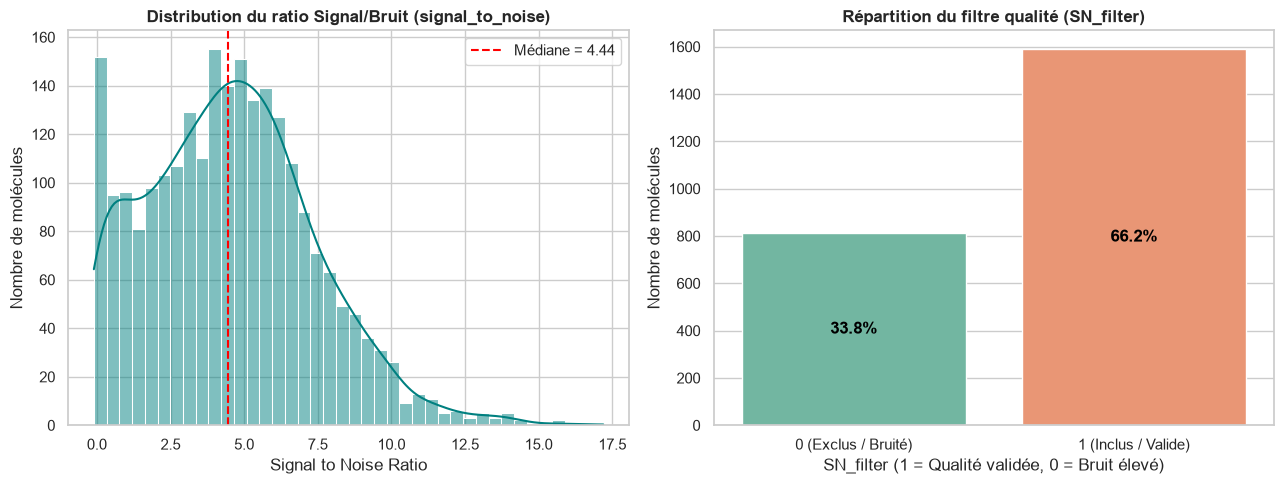

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Histogramme du ratio Signal/Bruit
sns.histplot(train_df['signal_to_noise'], bins=40, kde=True, ax=axes[0], color='teal')
axes[0].axvline(train_df['signal_to_noise'].median(), color='red', linestyle='--', 
                label=f"Médiane = {train_df['signal_to_noise'].median():.2f}")
axes[0].set_title("Distribution du ratio Signal/Bruit (signal_to_noise)", fontweight='bold')
axes[0].set_xlabel("Signal to Noise Ratio")
axes[0].set_ylabel("Nombre de molécules")
axes[0].legend()

# 2. Répartition du filtre binaire SN_filter
sn_counts = train_df['SN_filter'].value_counts()
sns.barplot(x=sn_counts.index, y=sn_counts.values, ax=axes[1], palette="Set2")
axes[1].set_title("Répartition du filtre qualité (SN_filter)", fontweight='bold')
axes[1].set_xlabel("SN_filter (1 = Qualité validée, 0 = Bruit élevé)")
axes[1].set_ylabel("Nombre de molécules")
axes[1].set_xticklabels(["0 (Exclus / Bruité)", "1 (Inclus / Valide)"])

# Annotation des pourcentages sur les barres
total = len(train_df)
for p in axes[1].patches:
    percentage = f"{100 * p.get_height() / total:.1f}%"
    axes[1].annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', fontsize=12, color='black', fontweight='bold')

plt.tight_layout()
# plt.savefig(f"{report_dir}/fig6_signal_to_noise_distribution.png", dpi=300)
# plt.close()
# print("✅ Figure 6 sauvegardée : fig6_signal_to_noise_distribution.png")
plt.show()

## 7. Profil moyen de réactivité/dégradation le long de la séquence (1 -> 68)

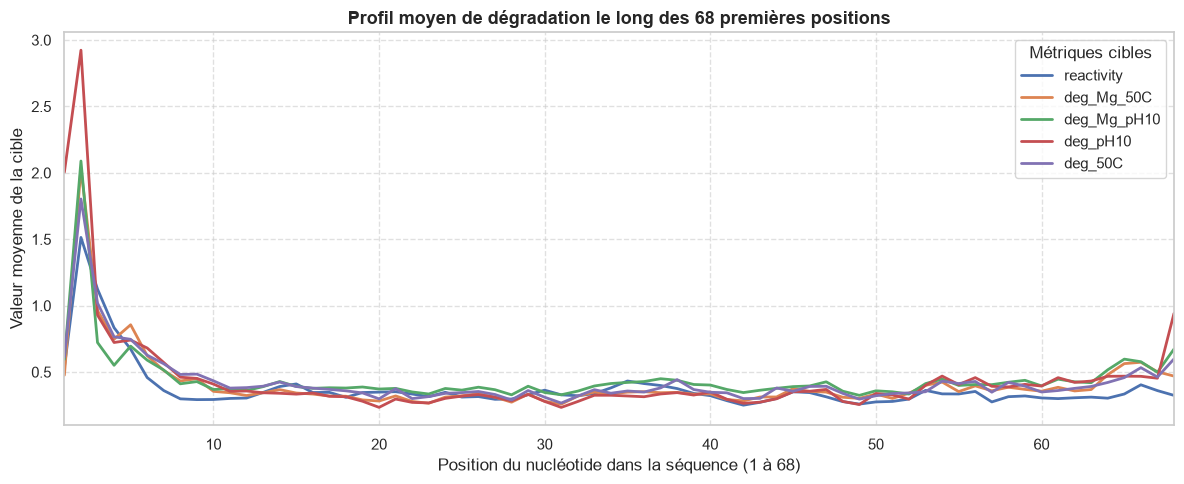

In [ ]:
target_cols = ['reactivity', 'deg_Mg_50C', 'deg_Mg_pH10', 'deg_pH10', 'deg_50C']

# Calcul de la moyenne par position (sur les 68 bases évaluées)
mean_profiles = {}
for col in target_cols:
    # Concatenation sous forme de matrice (2400 molécules x 68 positions)
    matrix = np.vstack(train_df[col].values)
    mean_profiles[col] = np.mean(matrix, axis=0)

df_profiles = pd.DataFrame(mean_profiles)
df_profiles['position'] = np.arange(1, 69)

plt.figure(figsize=(12, 5))
for col in target_cols:
    plt.plot(df_profiles['position'], df_profiles[col], label=col, linewidth=2)

plt.title("Profil moyen de dégradation le long des 68 premières positions", fontsize=13, fontweight='bold')
plt.xlabel("Position du nucléotide dans la séquence (1 à 68)")
plt.ylabel("Valeur moyenne de la cible")
plt.xlim(1, 68)
plt.legend(title="Métriques cibles", loc="upper right")
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
# plt.savefig(f"{report_dir}/fig7_degradation_profile_by_position.png", dpi=300)
# plt.close()
# print("✅ Figure 7 sauvegardée : fig7_degradation_profile_by_position.png")
plt.show()

## Correlation entre bpps et degradation 

Corrélation de Pearson  (BPPS max vs Réactivité) : -0.2821 (p-value: 0.00e+00)
Corrélation de Spearman (BPPS max vs Réactivité) : -0.5561 (p-value: 0.00e+00)


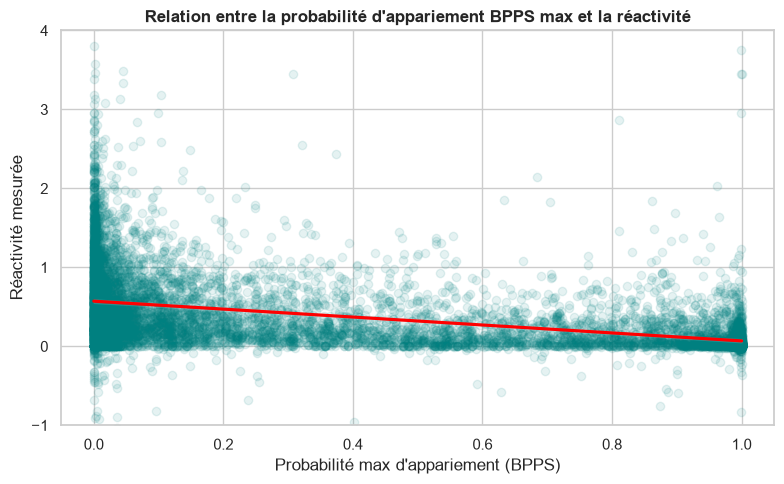

In [27]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import os

bpps_dir = "../data/bpps"

bpps_max_list = []
reactivity_list = []

# Extraction des valeurs sur l'ensemble du dataset
for idx, row in train_df.iterrows():
    bpps_path = os.path.join(bpps_dir, f"{row['id']}.npy")
    
    if os.path.exists(bpps_path):
        bpps_mat = np.load(bpps_path)
        # Probabilité max d'appariement pour les 68 premières positions
        max_prob_per_pos = np.max(bpps_mat[:68, :], axis=1)
        
        bpps_max_list.extend(max_prob_per_pos)
        reactivity_list.extend(row['reactivity'])

df_bpps_corr = pd.DataFrame({
    'max_bpps_prob': bpps_max_list,
    'reactivity': reactivity_list
})

# Calcul des corrélations de Pearson et Spearman
corr_p, p_val_p = stats.pearsonr(df_bpps_corr['max_bpps_prob'], df_bpps_corr['reactivity'])
corr_s, p_val_s = stats.spearmanr(df_bpps_corr['max_bpps_prob'], df_bpps_corr['reactivity'])

print(f"Corrélation de Pearson  (BPPS max vs Réactivité) : {corr_p:.4f} (p-value: {p_val_p:.2e})")
print(f"Corrélation de Spearman (BPPS max vs Réactivité) : {corr_s:.4f} (p-value: {p_val_s:.2e})")

# Visualisation
plt.figure(figsize=(8, 5))
sns.regplot(data=df_bpps_corr.sample(n=10000, random_state=42), 
            x='max_bpps_prob', y='reactivity', 
            scatter_kws={'alpha': 0.1, 'color': 'teal'}, line_kws={'color': 'red'})
plt.title("Relation entre la probabilité d'appariement BPPS max et la réactivité", fontsize=12, fontweight='bold')
plt.xlabel("Probabilité max d'appariement (BPPS)")
plt.ylabel("Réactivité mesurée")
plt.ylim(-1, 4)
plt.tight_layout()
plt.show()

--- TABLEAU DE RÉPARTITION DES TAUX DE DÉGRADATION PAR TYPE DE BOUCLE ---


reactivity                 deg_Mg_50C                 deg_Mg_pH10  \
                mean  median     std       mean  median     std        mean   
loop_type                                                                     
B             0.6288  0.5130  0.6446     0.5666  0.4290  0.7527      0.6597   
E             0.5629  0.4171  0.8972     0.6416  0.4502  1.1477      0.5861   
H             0.6774  0.5343  0.7798     0.5266  0.4111  0.7382      0.5920   
I             0.4457  0.3472  0.4027     0.4089  0.3060  0.4985      0.4495   
M             0.5224  0.4418  0.4069     0.5903  0.4890  0.5073      0.6266   
S             0.1791  0.0696  0.6450     0.2390  0.1224  0.8041      0.3124   
X             0.4725  0.4012  0.5053     0.5727  0.4821  0.6429      0.6053   

                          deg_pH10                 deg_50C                  
           median     std     mean  median     std    mean  median     std  
loop_type                                                                   
B          0.4659  0.7891   0.4973  0.3886  0.8631  0.4833  0.4259  0.8275  
E          0.3780  0.9468   0.8017  0.5216  1.7157  0.6585  0.5409  1.4034  
H          0.4243  0.7106   0.4498  0.3602  0.7957  0.5425  0.4507  1.0511  
I          0.3224  0.5039   0.3689  0.2921  0.4707  0.4287  0.3674  0.3830  
M          0.4904  0.5277   0.5944  0.4696  0.7992  0.5552  0.4993  0.4944  
S          0.2044  0.5865   0.2711  0.1631  1.2613  0.2720  0.1573  1.1133  
X          0.4831  0.5679   0.6277  0.4894  1.1655  0.5421  0.4872  0.9047

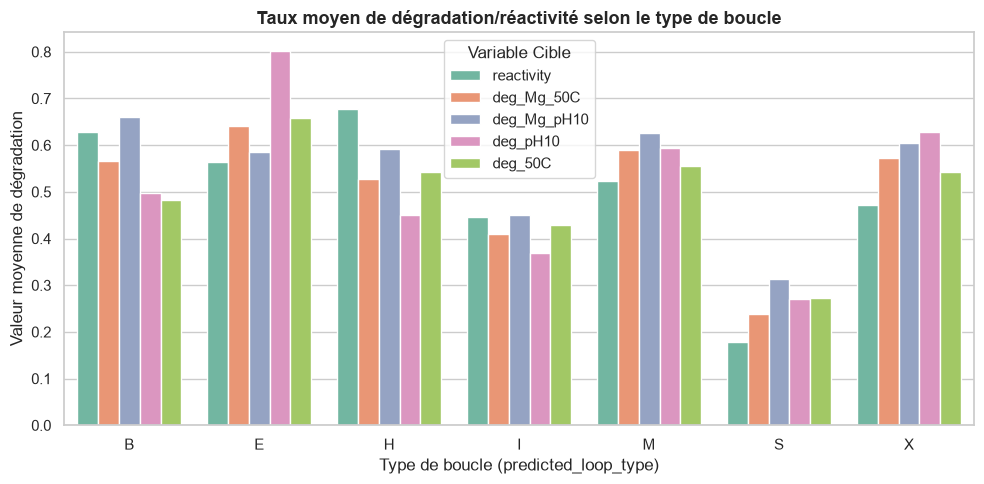

In [28]:
import pandas as pd
import numpy as np

target_cols = ['reactivity', 'deg_Mg_50C', 'deg_Mg_pH10', 'deg_pH10', 'deg_50C']

# 1. Aplatissement des données pour associer chaque nucléotide (0-67) à son type de boucle
flat_data = []

for idx, row in train_df.iterrows():
    loop_types = list(row['predicted_loop_type'][:68])
    for pos in range(68):
        entry = {'loop_type': loop_types[pos]}
        for target in target_cols:
            entry[target] = row[target][pos]
        flat_data.append(entry)

df_loops_all_targets = pd.DataFrame(flat_data)

# 2. Tableau récapitulatif par type de boucle (Moyenne & Médiane)
summary_table = df_loops_all_targets.groupby('loop_type')[target_cols].agg(['mean', 'median', 'std']).round(4)
print("--- TABLEAU DE RÉPARTITION DES TAUX DE DÉGRADATION PAR TYPE DE BOUCLE ---")
display(summary_table)

# 3. Visualisation comparative (Moyenne de dégradation par cible et par boucle)
df_mean_by_loop = df_loops_all_targets.groupby('loop_type')[target_cols].mean().reset_index()
df_melted = df_mean_by_loop.melt(id_vars='loop_type', var_name='Target', value_name='Taux moyen de dégradation')

plt.figure(figsize=(10, 5))
sns.barplot(data=df_melted, x='loop_type', y='Taux moyen de dégradation', hue='Target', palette='Set2')
plt.title("Taux moyen de dégradation/réactivité selon le type de boucle", fontsize=13, fontweight='bold')
plt.xlabel("Type de boucle (predicted_loop_type)")
plt.ylabel("Valeur moyenne de dégradation")
plt.legend(title="Variable Cible")
plt.tight_layout()
plt.show()